 ## Sviluppare una pipeline completa di Machine Learning per la Regressione, applicata al dataset multivariato Diabetes.

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.datasets import load_diabetes
from sklearn.neighbors import KNeighborsRegressor
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, learning_curve

## 1 - Data Exploration & Preprocessing

In [7]:
data = load_diabetes()
X = pd.DataFrame(data.data, columns = data.feature_names)
y = pd.Series(data.target, name = 'target')

df = X.copy()
df['target'] = y

print(df.describe())

display(df)

                age           sex  ...            s6      target
count  4.420000e+02  4.420000e+02  ...  4.420000e+02  442.000000
mean  -2.511817e-19  1.230790e-17  ...  1.130318e-17  152.133484
std    4.761905e-02  4.761905e-02  ...  4.761905e-02   77.093005
min   -1.072256e-01 -4.464164e-02  ... -1.377672e-01   25.000000
25%   -3.729927e-02 -4.464164e-02  ... -3.317903e-02   87.000000
50%    5.383060e-03 -4.464164e-02  ... -1.077698e-03  140.500000
75%    3.807591e-02  5.068012e-02  ...  2.791705e-02  211.500000
max    1.107267e-01  5.068012e-02  ...  1.356118e-01  346.000000

[8 rows x 11 columns]


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


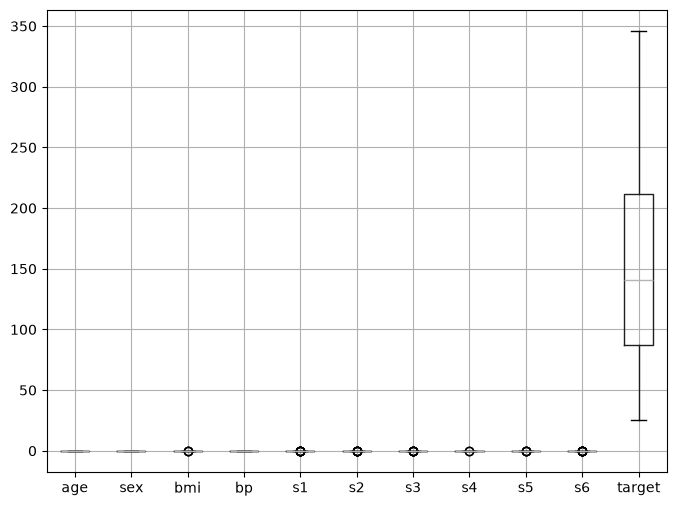

In [15]:
df.boxplot(figsize=(8,6))
plt.show()

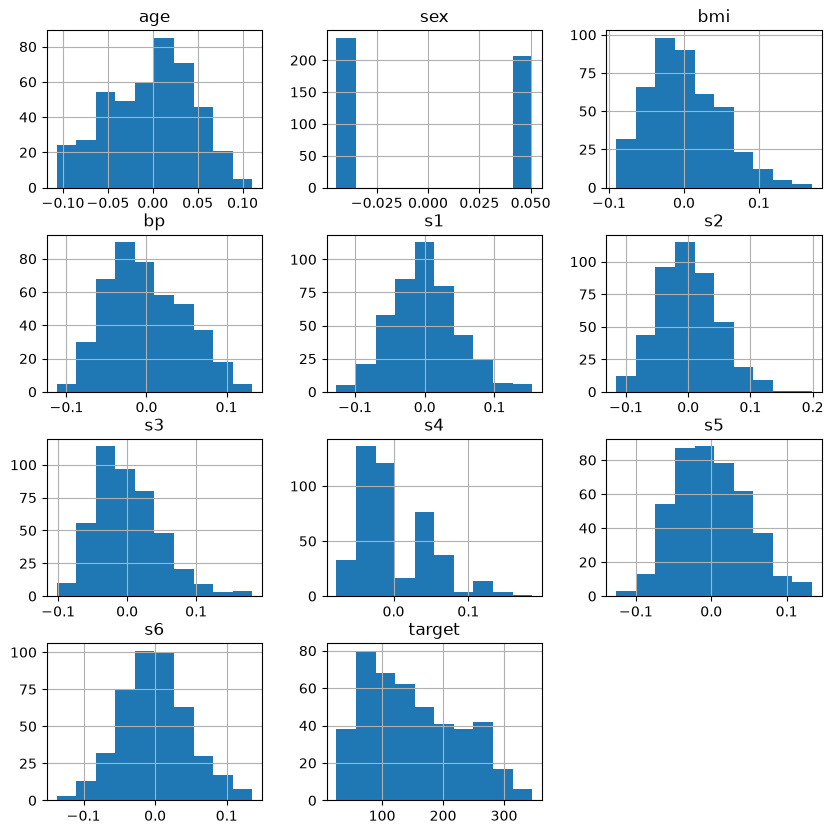

In [20]:
df.hist(figsize=(10, 10))
plt.show()

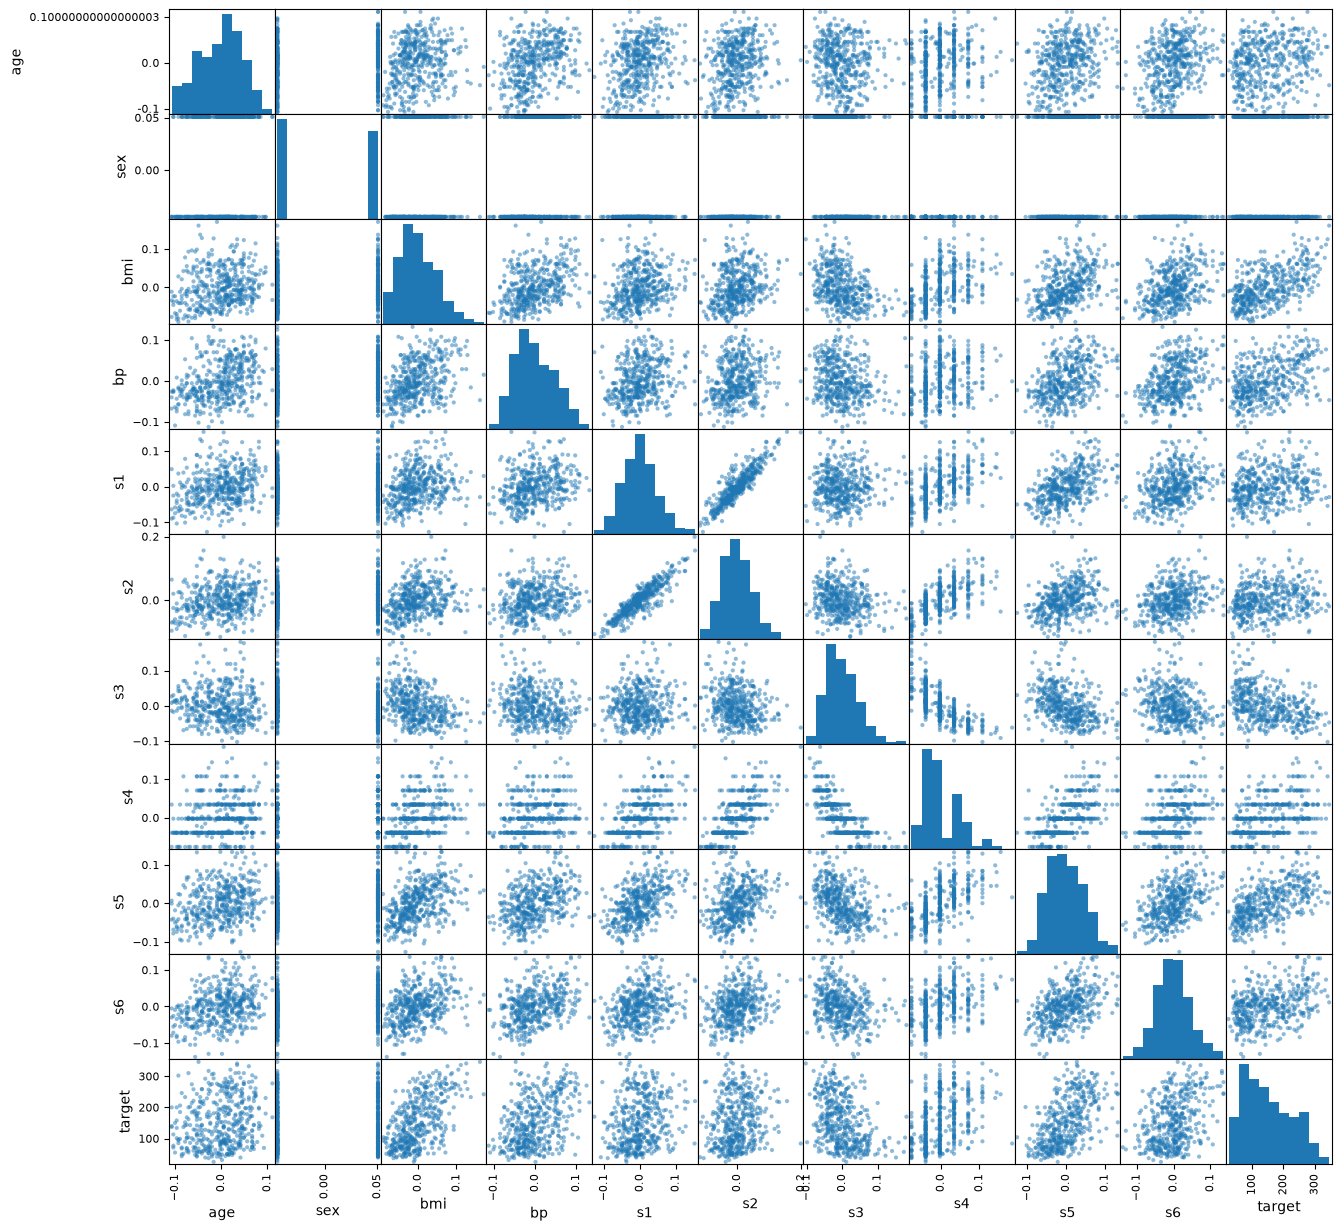

In [26]:
scatter_matrix(df, figsize=(15, 15))
plt.show()

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 2 - Confronto e Selezione Iniziale dei Modelli

In [32]:
#Regressione Lineare
K = 10
model_linear_reg = LinearRegression()
model_linear_reg.fit(X_train, y_train)
y_pred_linear = model_linear_reg.predict(X_test)

score_linear = cross_val_score(model_linear_reg, X_train, y_train, cv = K, scoring='neg_mean_squared_error')
nmse_mean_linear = np.mean(score_linear)

r2_linear = r2_score(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)

In [34]:
#Regressione Ridge
model_ridge = Ridge()
model_ridge.fit(X_train, y_train)
y_pred_ridge = model_ridge.predict(X_test)

score_ridge = cross_val_score(model_ridge, X_train, y_train, cv = K, scoring='neg_mean_squared_error')
nmse_mean_ridge = np.mean(score_ridge)

r2_ridge = r2_score(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)

In [ ]:
#Regressione Lasso
model_lasso = Lasso()
model_lasso.fit(X_train, y_train)
y_pred_lasso = model_lasso.predict(X_test)

score_lasso = cross_val_score(model_lasso, X_train, y_train, cv = K, scoring='neg_mean_squared_error')
nmse_mean_lasso = np.mean(score_lasso)

r2_lasso = r2_score(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)

In [37]:
#Regressione Support Vector Machine

svm_regression = SVR()
svm_regression.fit(X_train, y_train)
y_pred_svm = svm_regression.predict(X_test)

score_svm = cross_val_score(svm_regression, X_train, y_train, cv = K, scoring='neg_mean_squared_error')
nmse_svm = np.mean(score_svm)

r2_svm = r2_score(y_test, y_pred_svm)
mse_svm = mean_squared_error(y_test, y_pred_svm)

# Confronto tra i modelli

In [39]:
risultati = pd.DataFrame({
    'Modello': ['Linear', 'Ridge', 'Lasso', 'SVM'],
    'NMSE': [nmse_mean_linear, nmse_mean_ridge, nmse_mean_lasso, nmse_svm],
    'MSE': [mse_linear, mse_ridge, mse_lasso, mse_svm],
    'R2': [r2_linear, r2_ridge, r2_lasso, r2_svm]
})
display(risultati)

,Modello,NMSE,MSE,R2
0,Linear,-3119.578888,2900.193628,0.452603
1,Ridge,-3578.235324,3077.415939,0.419153
2,Lasso,-3993.839072,3403.575722,0.357592
3,SVM,-5257.568117,4333.285955,0.182114


## 3 - Hyperparameters Tuning

In [44]:
param_grid = {
    'C' : [0.1, 1, 10]
}
grid = GridSearchCV(cv = 10 ,estimator=svm_regression, scoring = 'neg_mean_squared_error', param_grid=param_grid)
grid.fit(X_train, y_train)

print(f"C:\t{grid.best_params_['C']}")
print(f"CV:\t{grid.best_score_:.3f}")

best_model = grid.best_estimator_
best_model. fit(X_train, y_train)
predictions = best_model.predict(X_test)

C:	10
CV:	-3403.093


In [45]:
final_mse = mean_squared_error(y_test, predictions)
final_r2 = r2_score(y_test, predictions)

print(f"MSE finale sul test: {final_mse:.3f}")
print(f"R2 finale sul test: {final_r2:.3f}")

MSE finale sul test: 2679.743
R2 finale sul test: 0.494


## 4 - Analisi delle Performance

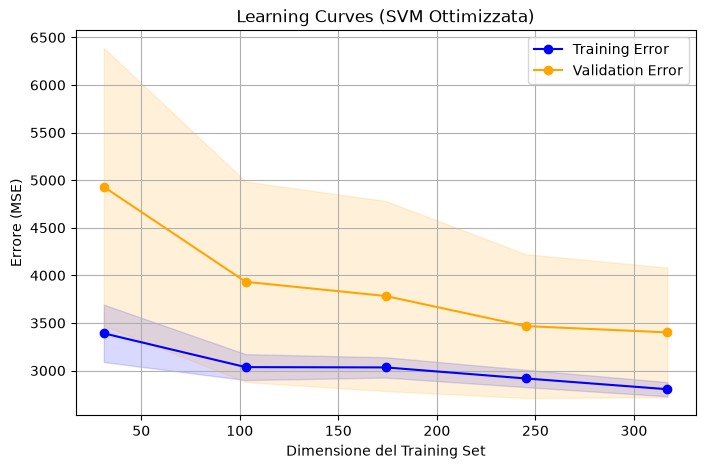

In [48]:
train_size, train_score, val_score = learning_curve(best_model, X_train, y_train, cv= 10, scoring='neg_mean_squared_error')

train_mean = -np.mean(train_score, axis=1)
train_std = np.std(train_score, axis=1)

val_mean = -np.mean(val_score, axis=1)
val_std = np.std(val_score, axis=1)


plt.figure(figsize=(8, 5))
plt.plot(train_size, train_mean, label='Training Error', color='blue', marker='o')
plt.fill_between(train_size, train_mean - train_std, train_mean + train_std, color='blue', alpha=0.15)

plt.plot(train_size, val_mean, label='Validation Error', color='orange', marker='o')
plt.fill_between(train_size, val_mean - val_std, val_mean + val_std, color='orange', alpha=0.15)

plt.title('Learning Curves (SVM Ottimizzata)')
plt.xlabel('Dimensione del Training Set')
plt.ylabel('Errore (MSE)')
plt.legend()
plt.grid(True)
plt.show()

#tra le 2 curve compare dello spazio, si arriva alla conclusione che sia presente dell'overfitting

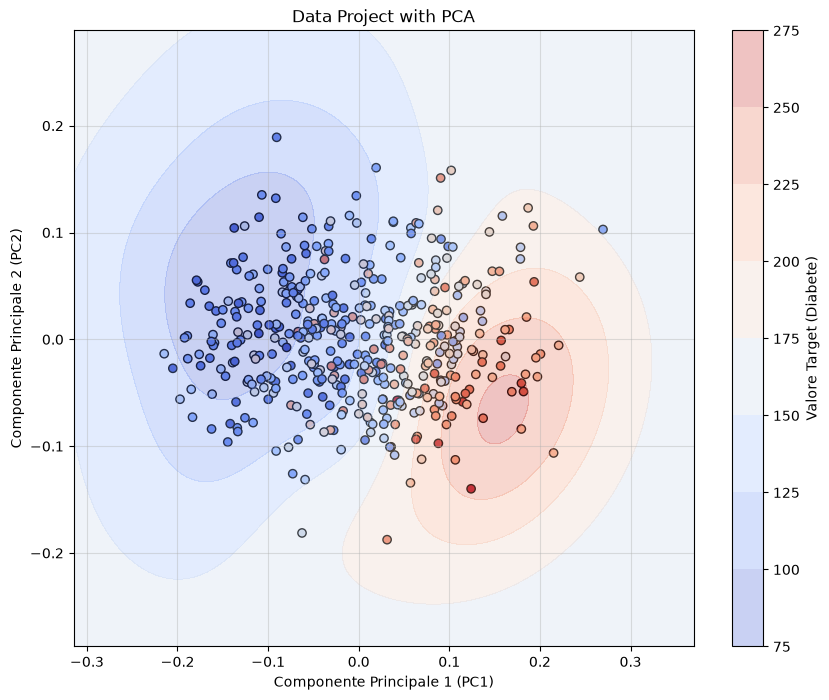

In [60]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

best_model.fit(X_pca, y)

plt.figure(figsize=(10,8))
scatter = plt.scatter(X_pca[:,0], X_pca[:, 1], c=y, cmap = 'coolwarm', edgecolors='k')

x_min, x_max =X_pca[:,0].min() -0.1, X_pca[:, 0].max() +0.1
y_min, y_max = X_pca[:, 1].min() - 0.1, X_pca[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
Z = best_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

contour = plt.contourf(xx, yy, Z, cmap='coolwarm', alpha=0.3, zorder=1)
plt.colorbar(contour, label='Valore Target (Diabete)') # Ottimale per variabili continue!

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.xlabel('Componente Principale 1 (PC1)')
plt.ylabel('Componente Principale 2 (PC2)')
plt.title('Data Project with PCA')
plt.grid(alpha = 0.4)
plt.show()